In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, LSTM, Dense, Dropout
import joblib

In [2]:
df = pd.read_csv('C:\\Users\\Chinmaya holla\\Desktop\\Airpollution\\Data\\Processed_data\\master_cleaned_data.csv')
df['Timestamp'] = pd.to_datetime(df['Timestamp'], dayfirst=True)
df_pivot = df.pivot_table(index='Timestamp', columns='Station', values='PM2_5')
df_pivot = df_pivot.interpolate(method='time').resample('D').mean().bfill().ffill()

In [4]:
# 2. Train/Test Split & Scaling
train_df = df_pivot[df_pivot.index.year < 2024]
test_df = df_pivot[df_pivot.index.year == 2024]

scaler = MinMaxScaler(feature_range=(0, 1))
scaled_train = scaler.fit_transform(train_df)
# We fit on train, but for the starting window of prediction, we need the very last data available (end of 2024)
# So we will scale the *entire* dataset to get the valid last window.
scaled_full = scaler.transform(df_pivot)

In [5]:
# 3. Create Sequences for Training
def create_sequences(data, time_steps=60):
    X, y = [], []
    for i in range(len(data) - time_steps):
        X.append(data[i : i + time_steps])
        y.append(data[i + time_steps])
    return np.array(X), np.array(y)

X_train, y_train = create_sequences(scaled_train, 60)

# 4. Build & Train Model (Quickly)
print("Training model...")
model = Sequential()
model.add(Conv1D(filters=64, kernel_size=3, activation='relu', input_shape=(X_train.shape[1], X_train.shape[2])))
model.add(MaxPooling1D(pool_size=2))
model.add(LSTM(units=50, return_sequences=False)) # Reduced units slightly for speed
model.add(Dropout(0.2))
model.add(Dense(units=X_train.shape[2]))
model.compile(optimizer='adam', loss='mean_squared_error')

# Train
model.fit(X_train, y_train, epochs=15, batch_size=32, verbose=0) # 15 epochs for demo speed

Training model...


c:\Users\Chinmaya holla\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [6]:
# 5. Predict Next 12 Months (365 Days)
print("Predicting next 12 months...")
future_days = 365
last_60_days = scaled_full[-60:] # Get last 60 days from the full 2024 dataset
current_batch = last_60_days.reshape(1, 60, len(df_pivot.columns))

future_predictions = []
for i in range(future_days):
    pred = model.predict(current_batch, verbose=0)
    future_predictions.append(pred[0])
    # Update batch
    current_batch = np.append(current_batch[:, 1:, :], pred.reshape(1, 1, len(df_pivot.columns)), axis=1)

# 6. Inverse Scale & Plot
future_predictions = scaler.inverse_transform(future_predictions)
prediction_dates = pd.date_range(start=df_pivot.index[-1] + pd.Timedelta(days=1), periods=future_days)

Predicting next 12 months...


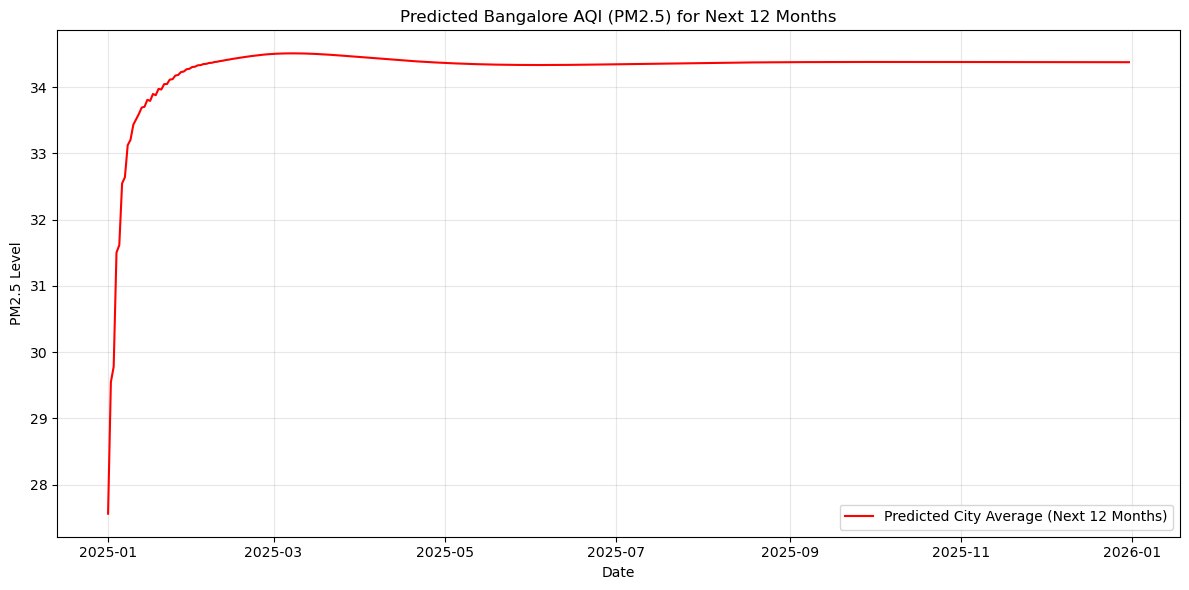

In [7]:
# Plotting
plt.figure(figsize=(12, 6))
# Plot City Average (Mean of all stations)
avg_prediction = np.mean(future_predictions, axis=1)

plt.plot(prediction_dates, avg_prediction, color='red', label='Predicted City Average (Next 12 Months)')
plt.title('Predicted Bangalore AQI (PM2.5) for Next 12 Months')
plt.xlabel('Date')
plt.ylabel('PM2.5 Level')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig('future_prediction.png')
plt.show()